# Validating cell-type annotaions
1. [Visualize QC statistics for single-tissue analyses](#section1)
2. [Visualize QC statistics for integrated analyses](#section2)
3. [Single-tissue analyses vs. Integrated analyses](#section3)
4. [Validate cell types with WNN approaches](#section4)
5. [Identify marker genes for each cell type](#section5)


In [ ]:
## Load package and the seurat object
library(Seurat)
library(data.table)
library(dplyr)
library(ggplot2)
library(plotly)
library(patchwork)
library(clusterProfiler)
library(org.Hs.eg.db)
library(enrichplot)
library(GOSemSim)
library(gridExtra)
library(slingshot)
source("../../code/make_plots.R")
options(repr.plot.width=14, repr.plot.height=10)

dataDIR <- "output/"
pal_atac <- readRDS("data/color_codes.RDS")
pal_rna <- pal_atac
names(pal_rna)[3:4] <- c("memCD4_T", "naiCD4_T")
pal_rna[3:4] = c("#208A42", "#bae4b3")
ct_order <- c(
  "Naive_B",
  "Memory_B",
  "NK",
  "CD8_T",
  "naiCD4_T",
  "memCD4_T",
  "Treg",
  "Other"
)

In [3]:
# Load Seurat Object
immune.combined<-readRDS(paste0(dataDIR, "lungs_spleens_integrated.RDS"))
immune.combined@active.assay<-"RNA"
lungs <- readRDS(paste0(dataDIR, "lungs_integrated.RDS"))
spleens <- readRDS(paste0(dataDIR, "spleens_integrated.RDS"))

Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



An object of class Seurat 
321146 features across 45820 samples within 4 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: ATAC, integrated, peaks
 2 dimensional reductions calculated: pca, umap

<a id='section1'></a>
## 1. Visualize QC statistics for single-tissue analyses

In [ ]:
lung<-readRDS("AGG_lungs/all_lungs_integrated_multi.rds")

p1 <- VlnPlot(lung, features = c("nCount_ATAC"),#, "nCount_RNA","percent.mt"), ncol = 3,
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p2 <- VlnPlot(lung, features = c("nCount_RNA"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p3 <- VlnPlot(lung, features = c("percent.mt"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 

#ggsave(p1|p2|p3, filename = "aggr_lung_statistics.pdf", width = 10, height = 4)

In [4]:
spleen<-readRDS("AGG_spleens/all_spleens_integrated_multi.rds")

p1 <- VlnPlot(lung, features = c("nCount_ATAC"),#, "nCount_RNA","percent.mt"), ncol = 3,
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p2 <- VlnPlot(lung, features = c("nCount_RNA"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p3 <- VlnPlot(lung, features = c("percent.mt"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 

#ggsave(p1|p2|p3, filename = "aggr_spleen_statistics.pdf", width = 10, height = 4)

<a id='section2'></a>
## 2. QC statistics for integrated analyses

In [ ]:
## UMAP visualization for integrated dataset colored by tissue, batch, cell type
p1 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "tissue.ident", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p2 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "batch", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p3 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "CellType", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p1 + p2 + p3

### Filtering out cluster 5 with high MT gene expression

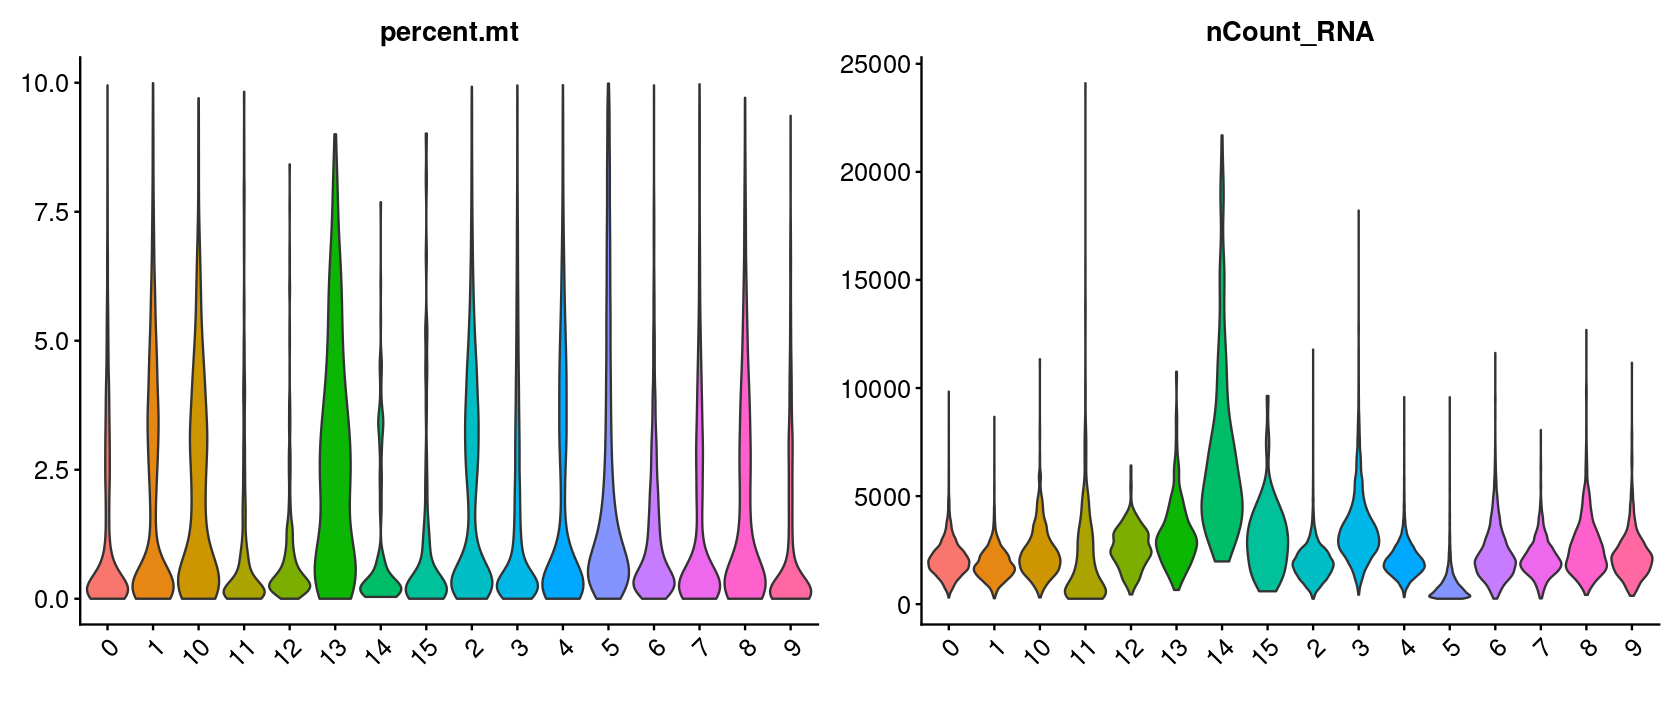

In [18]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <-VlnPlot(immune.combined, features = c("percent.mt"), 
            #split.by = "tissue.ident",
            group.by = "integrated_snn_res.0.5", pt.size = 0) + 
    theme(axis.text.x = element_text(size = 15),
          axis.text.y = element_text(size = 15),
          legend.position = "none") + xlab("")

p2 <-VlnPlot(immune.combined, features = c("nCount_RNA"), 
            #split.by = "tissue.ident",
            group.by = "integrated_snn_res.0.5", pt.size = 0) + 
    theme(axis.text.x = element_text(size = 15),
          axis.text.y = element_text(size = 15),
          legend.position = "none") + xlab("")

p1|p2

In [10]:
immune.combined <- subset(immune.combined, PriorClusters != "4" | tissue.ident == "spleens")

In [11]:
immune.combined

An object of class Seurat 
321146 features across 42863 samples within 4 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: ATAC, integrated, peaks
 2 dimensional reductions calculated: pca, umap

In [12]:
saveRDS(immune.combined, "output/lungs_spleens_integrated_sub.RDS")

In [ ]:
## Save Seurat object into a h5Dad object that can be used as inputs for CellTypist to annotate cell types
DefaultAssay(immune.combined)<-"RNA"

library("SeuratDisk")
SaveH5Seurat(immune.combined, 
             filename = "output/lungs_spleens_scRNA_only.h5Seurat")
Convert("output/lungs_spleens_scRNA_only.h5Seurat", dest = "h5ad")

In [1]:
# Run CellTypist to annotate cell types
# Python code
python code/annotate_clusters_CellTypist.py --h5ad output/lungs_spleens_scRNA_only.h5ad --cluster_col CellType, --out output/predicted_labels_integrated_removeDup.txt

ERROR: Error: object 'python' not found


<a id='section3'></a>

## 3. Single-tissue vs. Integrated analyses

In [3]:
lungs_labels <- fread("output/lungs_integrated_noDoublets.csv")
lungs@meta.data$majority_voting <- lungs_labels$majority_voting[match(rownames(lungs@meta.data), lungs_labels$V1)]
spleens_labels <- fread("output/spleens_integrated_noDoublets.csv")
spleens@meta.data$majority_voting <- spleens_labels$majority_voting[match(rownames(spleens@meta.data), spleens_labels$V1)]
labels <- fread("output/predicted_labels_integrated_removeDup.txt")

In [4]:
# Rename cell types for simplicity and consistency
lungs$SingleTissue <- 
    factor(lungs$majority_voting,
           labels = c("NK",
                      "NK",
                      "Other",
                      "Other",
                      "Memory_B",
                      "Naive_B",
                      "Other",
                      "Treg",
                      "naiCD4_T",
                      "memCD4_T",
                      "CD8_T"))
spleens$SingleTissue <- 
    factor(spleens$majority_voting,
           labels = c("NK",
                      "NK",
                      "Other",
                      "Memory_B",
                      "Naive_B",
                      "naiCD4_T",
                      "CD8_T"))

immune.combined$majority_voting <- labels$majority_voting
immune.combined$CellType <- immune.combined$majority_voting
immune.combined$CellType <-
    factor(immune.combined$CellType,
           levels = levels(factor(immune.combined$majority_voting)),
           label = c("Memory_B",
                         "NK",
                         "NK",
                         "Other",
                         "Other",
                         "Memory_B",
                         "Naive_B",
                         "Treg",
                         "naiCD4_T",
                         "memCD4_T",
                         "CD8_T"))

In [ ]:
# Add integrated annotations to spleen-only or lungs-only Seurat objects
spleens@active.assay <- "RNA"
cluster <- immune.combined@meta.data %>% filter(tissue.ident == "lungs" & grepl("CD4_T", CellType))
clusterDF <- data.frame(Barcode = rownames(cluster), CellType = cluster$CellType)
spleens@meta.data$Integrated <- immune.combined@meta.data$CellType[match(rownames(spleens@meta.data), rownames(immune.combined@meta.data))]
lungs@meta.data$Integrated <- immune.combined@meta.data$CellType[match(rownames(lungs@meta.data), rownames(immune.combined@meta.data))]

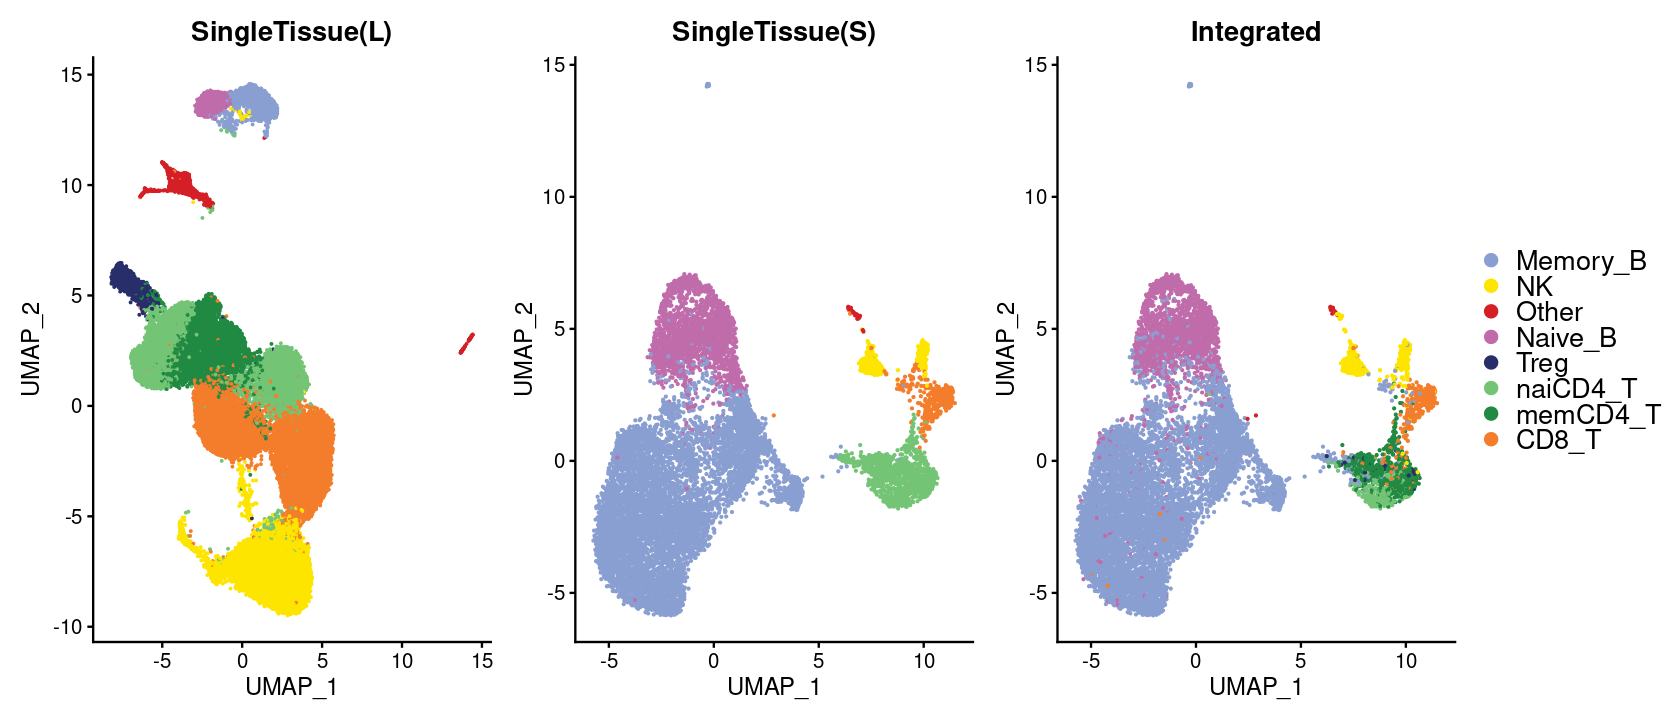

In [32]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(lungs, reduction = "umap", group.by = "SingleTissue", 
              cols = pal_rna, label.size = 5, label=FALSE, repel = TRUE) + ggtitle("SingleTissue(L)")
p2 <- DimPlot(spleens, reduction = "umap", group.by = "SingleTissue",
              label.size = 5, label=FALSE, cols = pal_rna) + ggtitle("SingleTissue(S)")
p3 <- DimPlot(spleens, reduction = "umap", group.by = "Integrated", 
              label.size = 5, label = FALSE, repel = TRUE, cols = pal_rna) + ggtitle("Integrated")
p <- (p1 + p2) & NoLegend()
p + (p3 + theme(legend.text = element_text(size = 16)))

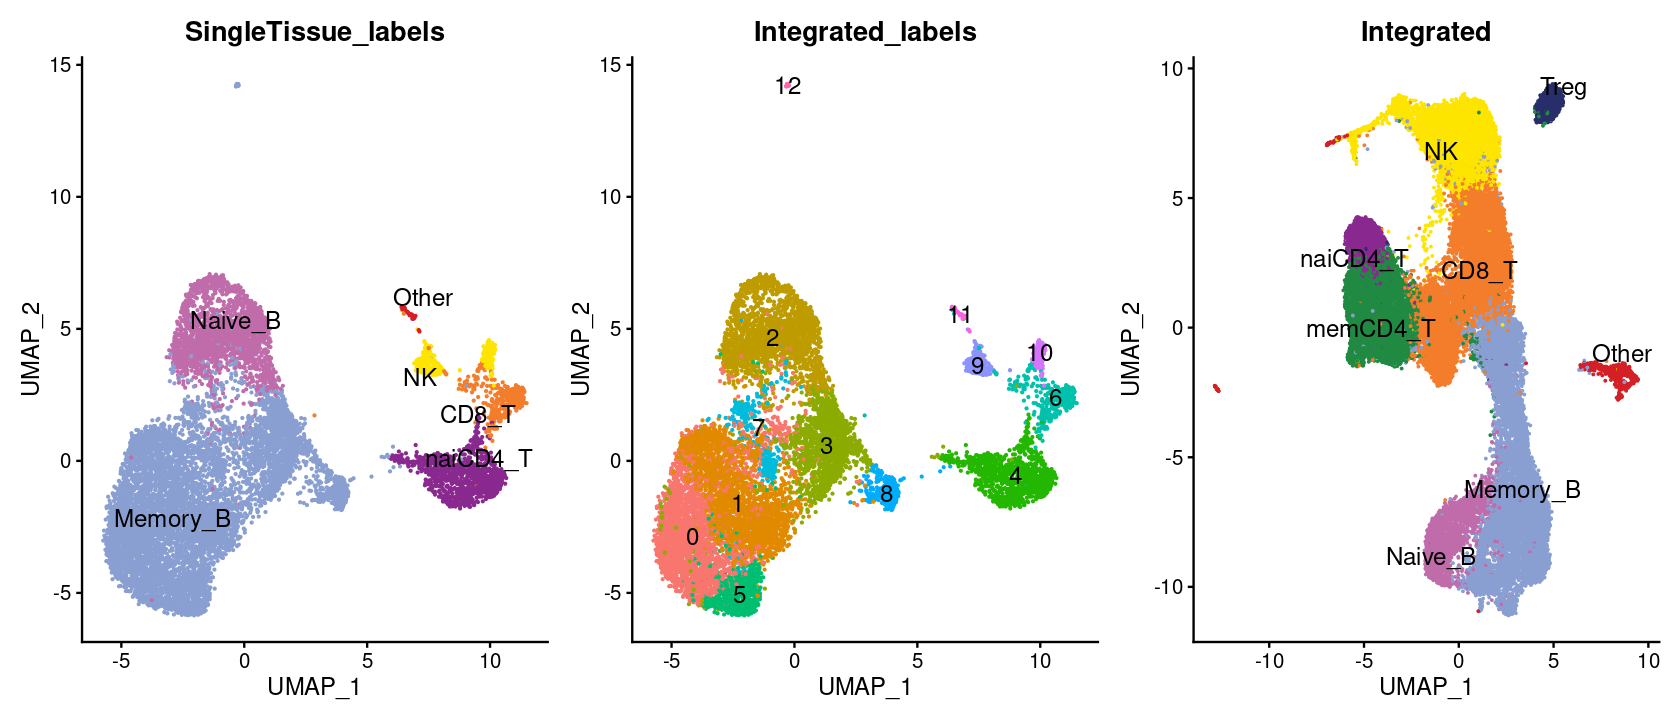

In [8]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(spleens, reduction = "umap", group.by = "SingleTissue", 
              cols = pal_rna, label.size = 5, label=TRUE, repel = TRUE) + ggtitle("SingleTissue_labels")
p2 <- DimPlot(spleens, reduction = "umap", group.by = "integrated_snn_res.0.5",
              label.size = 5, label=TRUE) + ggtitle("Integrated_labels")
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "CellType", 
              label.size = 5, label = TRUE, repel = TRUE, cols = pal_rna) + ggtitle("Integrated")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))

In [5]:
# Compute Jaccard Index to compare different annotation approaches
jaccard <- function(a, b) {
    intersection = sum(a == b, na.rm = TRUE)
    union = length(a) + length(b) - intersection
    return (c(intersection, union, intersection/union))
}

labels_tbl <- rbind(
    data.frame(SingleTissue = lungs@meta.data$SingleTissue,
                         CellBarcode = rownames(lungs@meta.data)),
    data.frame(SingleTissue = spleens@meta.data$SingleTissue,
                         CellBarcode = rownames(spleens@meta.data)))
labels_tbl$Integrated <- immune.combined$CellType[match(labels_tbl$CellBarcode, 
                                                        rownames(immune.combined@meta.data))]

In [6]:
print("Overall similarity score:")
jaccard(labels_tbl$SingleTissue, labels_tbl$Integrated)


[1] "Overall similarity score:"


[1] 3.844400e+04 5.319600e+04 7.226859e-01

In [8]:
print("Similarity scores by cell type:")
similarity_tbl <-
t(sapply(unique(as.character(labels_tbl$SingleTissue)), function(i) {
    df <- labels_tbl %>% filter(SingleTissue == i)
    return(jaccard(df$SingleTissue, df$Integrated))
}))
similarity_tbl <- data.frame(
    CellType = rownames(similarity_tbl),
    Score = similarity_tbl[, 3])
similarity_tbl

,CellType,Score
,<chr>,<dbl>
NK,NK,0.9334161
naiCD4_T,naiCD4_T,0.1606977
CD8_T,CD8_T,0.9043397
memCD4_T,memCD4_T,0.8577438
Naive_B,Naive_B,0.8519845
Treg,Treg,0.8889868
Memory_B,Memory_B,0.9215726
Other,Other,0.9100204


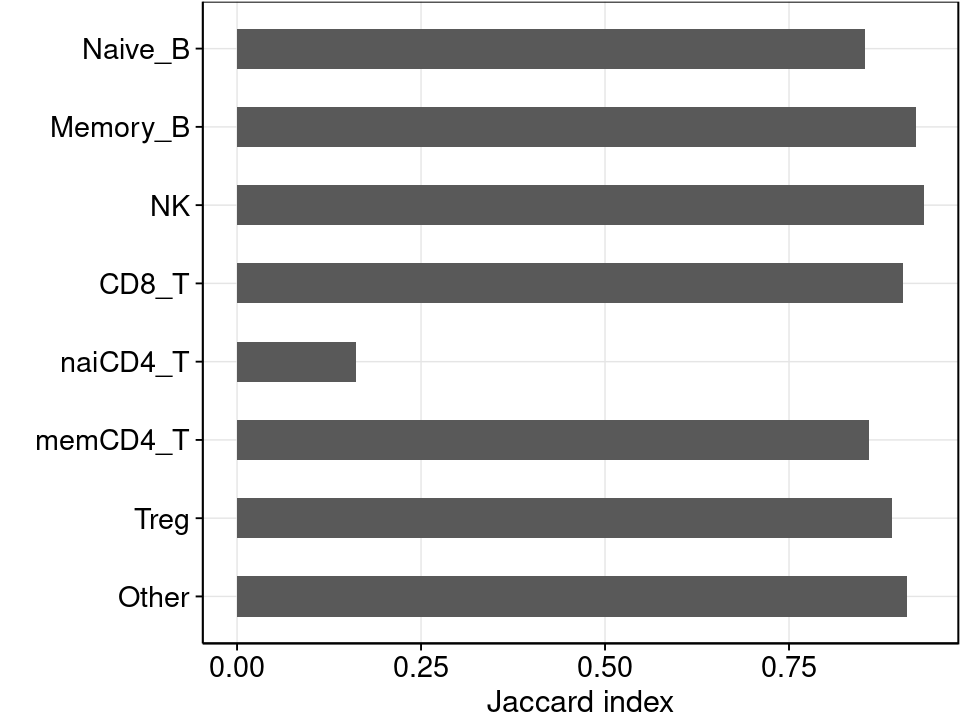

In [18]:
options(repr.plot.width=8, repr.plot.height=6)
ggplot(similarity_tbl %>% mutate(CellType = factor(CellType, levels = rev(ct_order))), 
       aes(y = CellType,
           x = Score)) + 
geom_col(width = 0.5) + 
theme_pub(base_size = 17) + 
ylab("") + xlab("Jaccard index")


### Final UMAP plots for RNA-seq library

In [19]:
immune.combined <- readRDS("../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

In [4]:
# Extract RNA-seq count matrix and convert it to CPM
pseubulk_list <- AggregateExpression(
  object = seurat_obj,
  assays = "RNA",
  slot = "counts",       # Use raw counts
  group.by = c("celltype", "sample_id"),
  return.seurat = FALSE  # Returns a list of matrices
)

# Extract the matrix for the RNA assay
counts_matrix <- pseubulk_list$RNA

# 2. Convert raw pseudobulk counts to CPM
cpm_matrix <- apply(counts_matrix, 2, function(x) {
  (x / sum(x)) * 1e6
})

# Verify CPM sums to 1 million per sample (column)
colSums(cpm_matrix)

Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



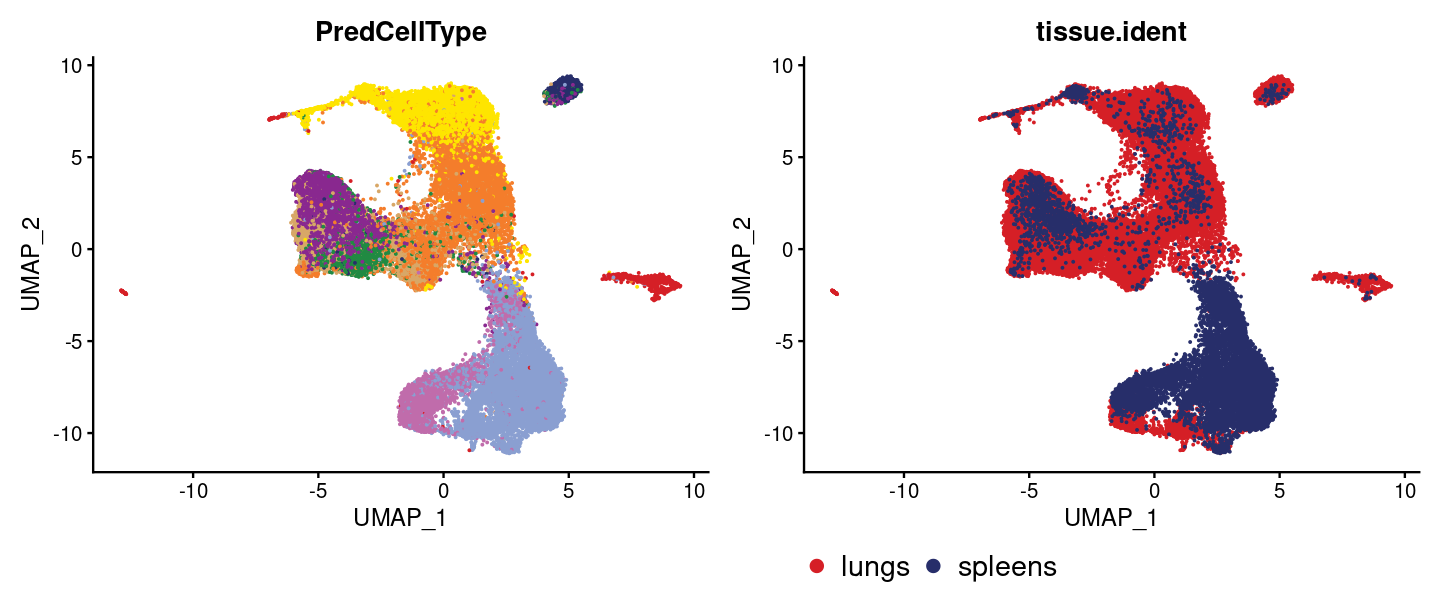

In [10]:
options(repr.plot.width=12, repr.plot.height=5)
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "PredCellType",
              label.size = 5, label=FALSE, cols = pal_atac) + theme(legend.position="none", legend.text = element_text(size = 17))
p2 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", 
              label.size = 5, label = FALSE, repel = TRUE, cols = c("#D51F26", "#272E6A"))+
                theme(legend.position="bottom", legend.text = element_text(size = 17))
p1 + p2 

## 4 Validate cell types with Weighted Nearest Neighbor (WNN) approach

In [ ]:
# Run WNN analysis on integrated Seurat object
immune.combined <- readRDS("output/lungs_spleens_integrated_sub.RDS")
DefaultAssay(immune.combined) <- "integrated"
immune.combined <- immune.combined %>% FindVariableFeatures() %>% ScaleData() %>% RunPCA() %>% RunUMAP(dims = 1:50, reduction.name = 'umap.rna', reduction.key = 'rnaUMAP_')

DefaultAssay(immune.combined) <- "ATAC"
immune.combined <- RunTFIDF(immune.combined)
immune.combined <- FindTopFeatures(immune.combined, min.cutoff = 'q0')
immune.combined <- RunSVD(immune.combined)
immune.combined <- RunUMAP(immune.combined, reduction = 'lsi', dims = 2:50, reduction.name = "umap.atac", reduction.key = "atacUMAP_")

immune.combined <- FindMultiModalNeighbors(immune.combined, reduction.list = list("pca", "lsi"), dims.list = list(1:50, 2:50))
immune.combined <- RunUMAP(immune.combined, nn.name = "weighted.nn", reduction.name = "wnn.umap", reduction.key = "wnnUMAP_")
immune.combined <- FindClusters(immune.combined, graph.name = "wsnn", algorithm = 3, resolution = 0.2, verbose = FALSE)

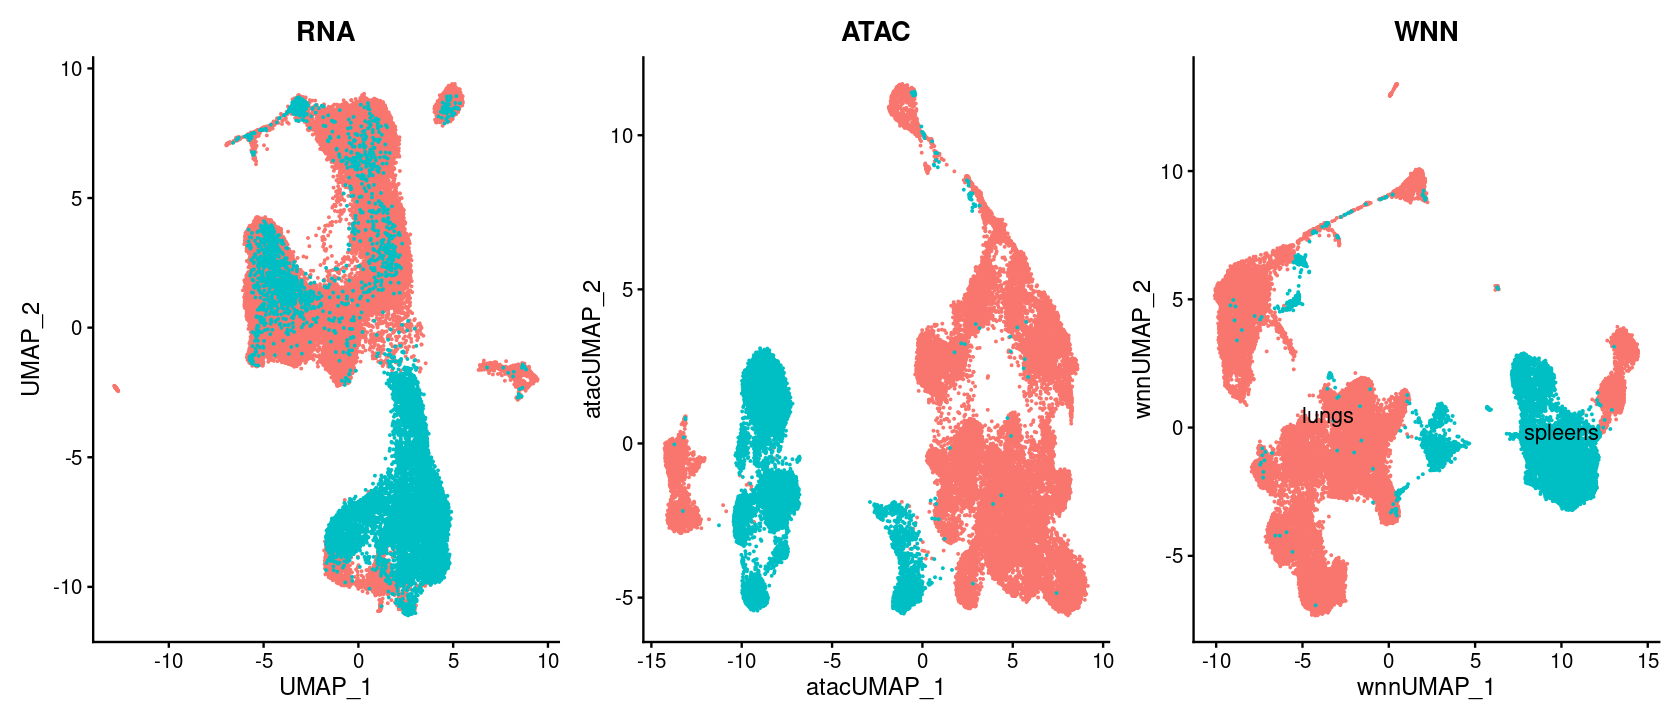

In [20]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("RNA")
p2 <- DimPlot(immune.combined, reduction = "umap.atac", group.by = "tissue.ident", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("ATAC")
p3 <- DimPlot(immune.combined, reduction = "wnn.umap", group.by = "tissue.ident", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p4 <- DimPlot(lungs_wnn, reduction = "wnn.umap", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))


In [6]:
## Assign cell type annotations using CellTypist
annot <- read.csv("../../output/predicted_labels_integrated_removeDup_wnn.txt")
immune.combined$wnnMajorityVoting <- annot$majority_voting[match(rownames(immune.combined@meta.data), annot$X)]
immune.combined$wnnCellType <- 
    factor(immune.combined$wnnMajorityVoting, 
           labels = c("NK","NK","Other","Other",
                      "Other","Other","Memory_B",
                      "Naive_B","Treg","naiCD4_T","CD8_T"))

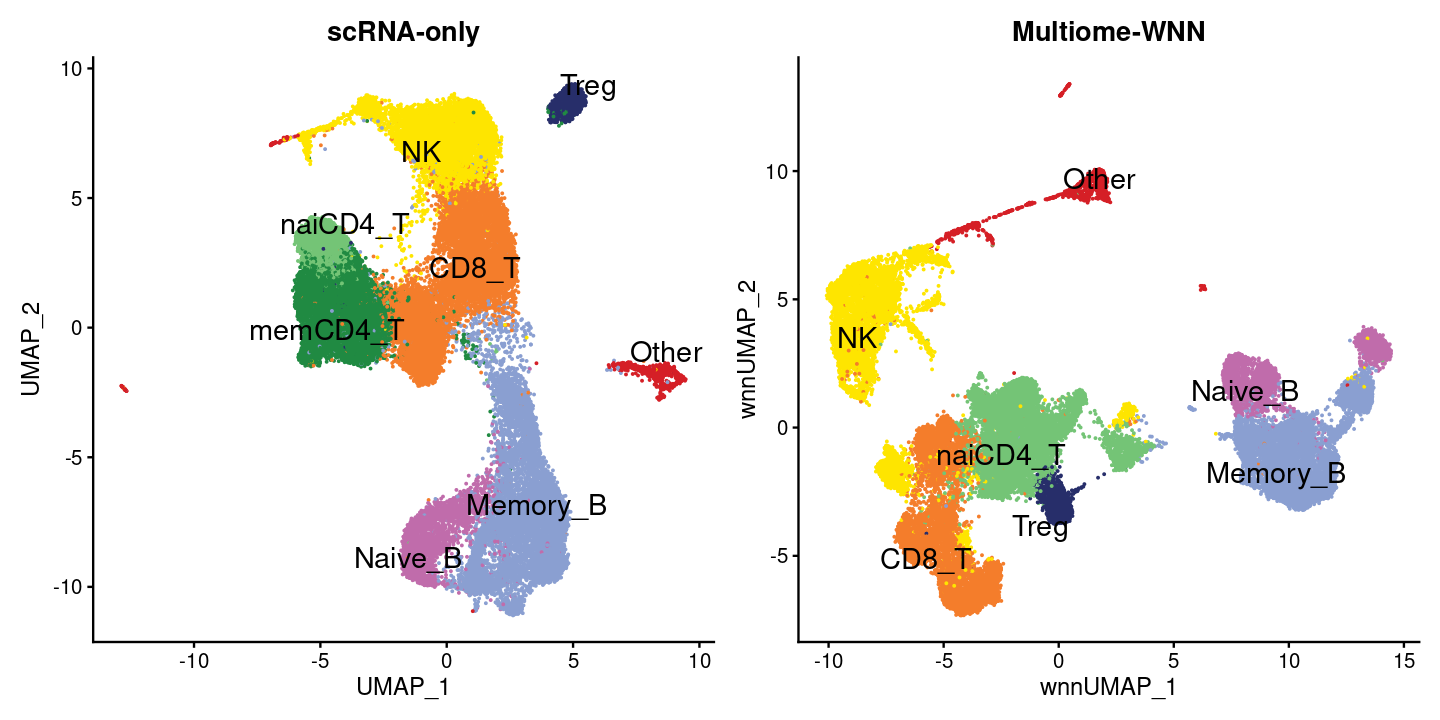

In [17]:
options(repr.plot.width=12, repr.plot.height=6)
integrated <- readRDS("output/lungs_spleens_integrated_sub.RDS")
p1 <- DimPlot(immune.combined, reduction = "wnn.umap",  group.by = "wnnCellType", cols = pal_rna, 
              label = TRUE, label.size = 6, repel = TRUE) + ggtitle("Multiome-WNN")
p2 <- DimPlot(integrated, reduction = "umap", group.by = "CellType", cols = pal_rna, 
              label = TRUE, label.size = 6, repel = TRUE) + ggtitle("scRNA-only")
p2 + p1 & NoLegend()

In [38]:
sim_metrics <-
t(sapply(levels(immune.combined$CellType),function(i) {
    ct_vector = as.character(immune.combined$CellType)
    jaccard(ct_vector[ct_vector == i], 
            as.character(immune.combined$wnnCellType)[ct_vector == i])
    }))
sim_metrics <- data.frame(
    CellType = rownames(sim_metrics),
    Score = sim_metrics[, 3])


In [18]:
## Compared with rPCA integrated approach
print(sprintf("Overall similarity score: %s", jaccard(immune.combined$majority_voting, immune.combined$wsnn_MajorityVoting)))

t(sapply(unique(immune.combined$majority_voting), function(i){
    idx = which(immune.combined$majority_voting == i)
    return(jaccard(immune.combined$majority_voting[idx], immune.combined$wsnn_MajorityVoting[idx]))
    }))

[1] "Overall similarity score: 33093"            
[2] "Overall similarity score: 74201"            
[3] "Overall similarity score: 0.445991293917872"


Memory B cells,9341,22247,0.4198768
CD16+ NK cells,6263,9259,0.6764229
Tcm/Naive helper T cells,1319,14413,0.0915146
Tem/Trm cytotoxic T cells,11382,13880,0.8200288
Type 17 helper T cells,0,5600,0.0000000
ILC3,0,1102,0.0000000
Plasma cells,62,62,1.0000000
Naive B cells,1679,4089,0.4106138
Regulatory T cells,1257,1509,0.8330020
Classical monocytes,1024,1040,0.9846154
CD16- NK cells,676,864,0.7824074


<a id='section5'></a>

## 5 Identify marker genes for each cell type

In [ ]:
# Identify marker genes for lung CD4 T cells 
pseubulk_list <- AggregateExpression(
  object = seurat_obj,
  assays = "RNA",
  slot = "counts",       # Use raw counts
  group.by = c("celltype", "sample_id"),
  return.seurat = FALSE  # Returns a list of matrices
)

immune.combined$grnCellType <- gsub("nai", "", gsub("mem", "", immune.combined$CellType))

Idents(immune.combined) <- immune.combined$grnCellType

marker_genes<- FindMarkers(subset(immune.combined, tissue.ident=="lungs"),
                           ident.1 =  "CD4_T", ident.2 = "Memory_B") 

saveRDS(marker_genes, "../../output/output_dir/remove_dup/dictys/lung_CD4_T_vs_Mem_B_DEG.RDS")

In [ ]:
## Differential expression analysis across cell types with the Wilcoxon rank sum test

immune.markers <- FindAllMarkers(immune.combined,
                                 group.by = immune.combined$CellType,
                                 only.pos = TRUE)
immune.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1)

immune.markers %>%
    group_by(cluster) %>%
    dplyr::filter(p_val_adj < 0.001) %>%
    arrange(desc(avg_log2FC)) %>%
    slice_head(n = 5) %>%
    ungroup() -> top5

### Dotplots for the expression of known marker genes across immune cells

In [3]:
markerGenes <- c(
    "CD69","IGHD", 
    "IL4R", "MS4A1",
      "BANK1", 
      "GNLY", "NKG7",
      "CD8B", "ITGAE", "GZMK",
      "LEF1", "TCF7", "IL7R",
      "CD28", "PRDM1", "CCR7",
      "CTLA4", "IL2RA", "FOXP3")

In [6]:
immune.combined$CellType <- 
    factor(immune.combined$CellType, 
           levels = rev(ct_order))
Idents(immune.combined) <- immune.combined$CellType
p2 <-
    DotPlot(
        subset(immune.combined, subset= CellType != "Other"),
        features = markerGenes) + 
    RotatedAxis() + xlab("") + ylab("") 
   

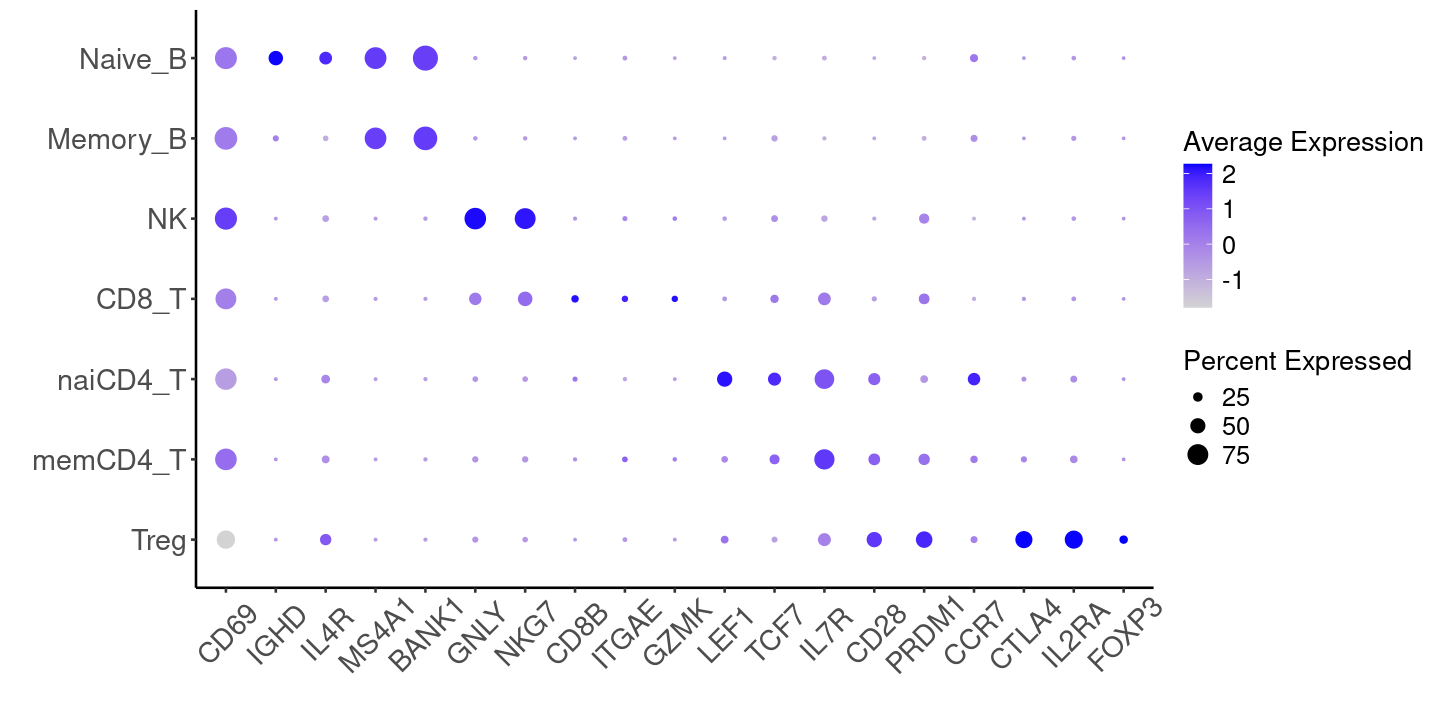

In [9]:
options(repr.plot.width=12, repr.plot.height= 6)
p2 + theme_classic(base_size = 12) + 
    theme(axis.text.x = element_text(size = 17, angle = 45, vjust=0.6),
          axis.text.y = element_text(size = 17),
          legend.title = element_text(size = 16),
          legend.text = element_text(size = 15))

### Dotplot split by tissue

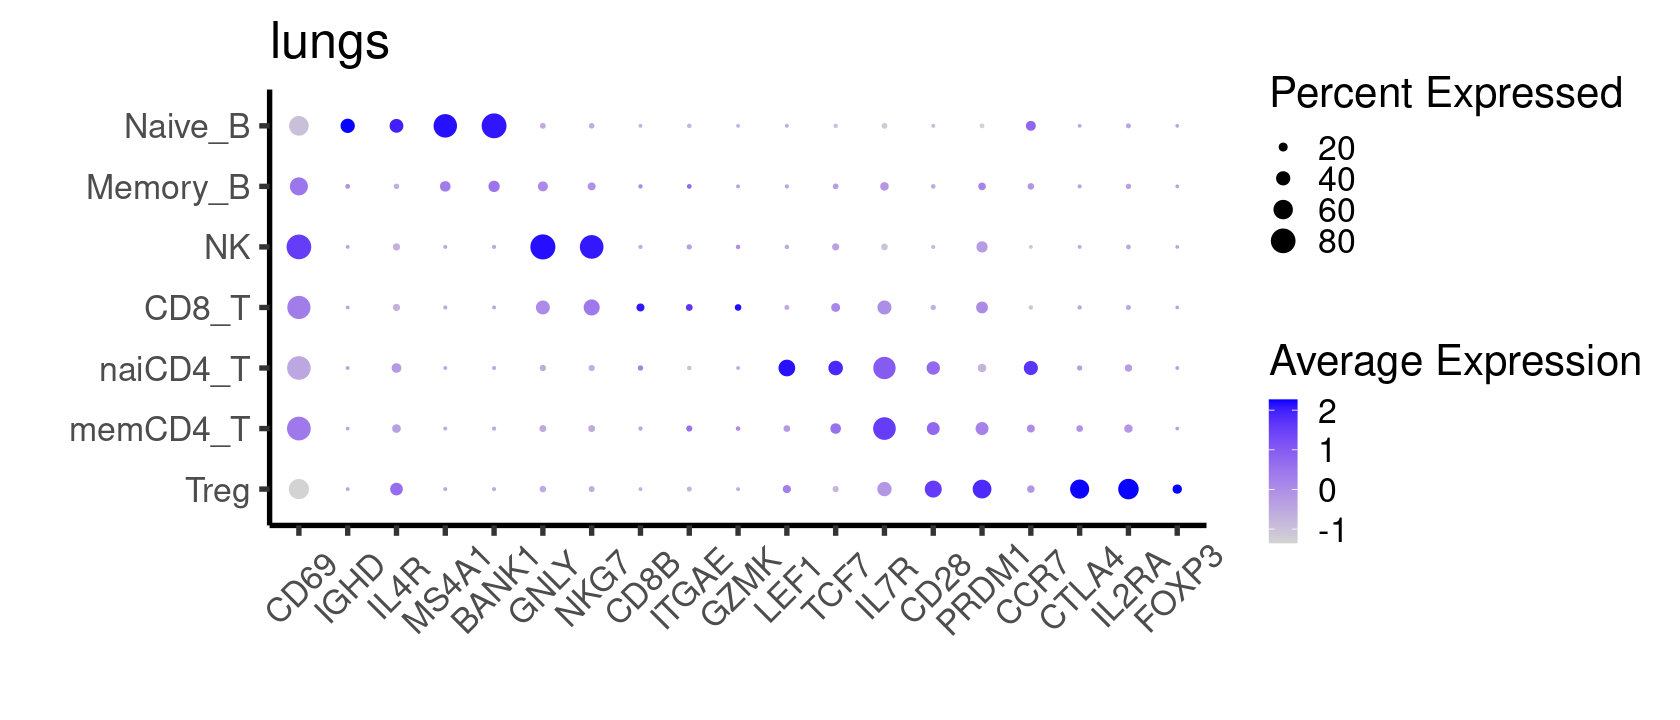

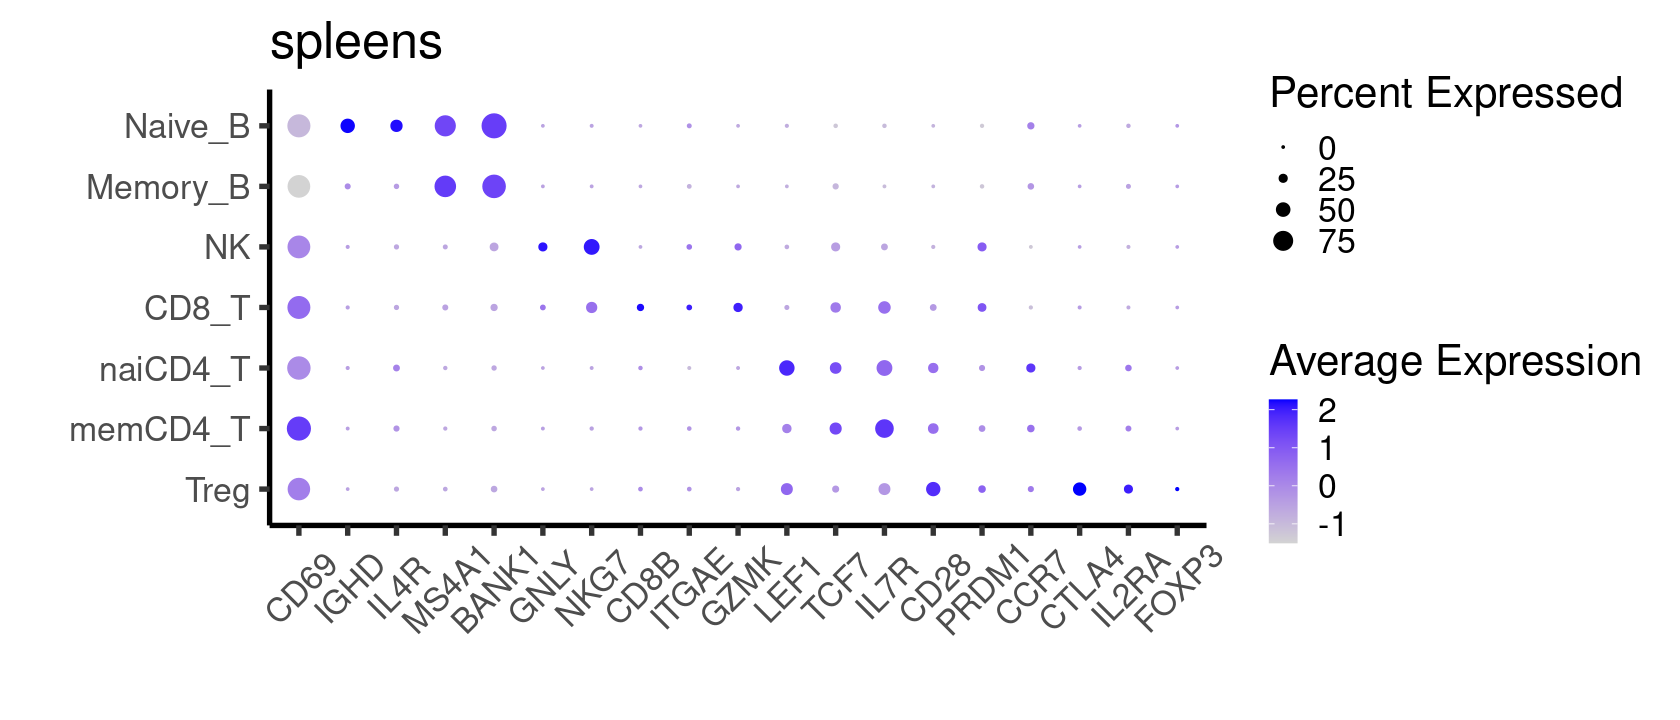

In [81]:
options(repr.plot.width=14, repr.plot.height= 6)
DotPlot(subset(immune.combined, CellType != "Other" & tissue.ident == "lungs"), 
        features = markerGenes) + 
        RotatedAxis() + xlab("") + ylab("") + 
theme_classic(base_size = 25) + 
theme(axis.text.x = element_text(angle = 45, vjust=0.6)) + ggtitle("lungs")

DotPlot(subset(immune.combined, CellType != "Other" & tissue.ident == "spleens"), 
        features = markerGenes) + 
        RotatedAxis() + xlab("") + ylab("") + 
theme_classic(base_size = 25) + 
theme(axis.text.x = element_text(angle = 45, vjust=0.6)) + ggtitle("spleens")